# Задача 3. Выбор из N и петли — анализ сырых логов

Источники: `logs/part_a.jsonl` (каждый запуск выбора инструмента) и `logs/part_b.jsonl` (каждый эпизод агента).
Неудачные и незавершённые запуски **не выбрасываются**: они входят в знаменатель как ошибки.
Доверительные интервалы — 95 % перцентильный бутстрэп (10 000 повторов), ресэмплируются **запросы**
(для части B — задачи), а не отдельные запуски.

In [1]:
import json, sys
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'consult_mcp').is_dir())
sys.path.insert(0, str(ROOT))
from experiment.common import bootstrap_ci, RESULTS, CHAT_MODEL, EMBED_MODEL, NUM_CTX, TEMPERATURE
RESULTS.mkdir(parents=True, exist_ok=True)
A = pd.DataFrame([json.loads(l) for l in open(ROOT/'experiment/logs/part_a.jsonl', encoding='utf-8')])
queries = pd.DataFrame(json.load(open(ROOT/'experiment/data/queries.json', encoding='utf-8')))
pool = pd.DataFrame(json.load(open(ROOT/'experiment/data/tool_pool.json', encoding='utf-8')))
print('модель:', CHAT_MODEL, '| эмбеддинги:', EMBED_MODEL, '| num_ctx:', NUM_CTX, '| temperature:', TEMPERATURE)
print('пул:', pool.kind.value_counts().to_dict(), '| запросов:', len(queries))
print('записей в логе A:', len(A), '| ожидалось:', len(queries)*4*2*3)
print(A.groupby(['N','variant']).status.value_counts().unstack(fill_value=0))

модель: qwen2.5:3b | эмбеддинги: bge-m3 | num_ctx: 16384 | temperature: 0.7
пул: {'public': 69, 'near': 25, 'own': 6} | запросов: 30
записей в логе A: 720 | ожидалось: 720
status       ok
N   variant    
5   A        90
    B        90
20  A        90
    B        90
50  A        90
    B        90
100 A        90
    B        90


## Часть A. Полнота лога и неудачные запуски

In [2]:
expected = pd.MultiIndex.from_product([queries.id, [5,20,50,100], ['A','B'], [1,2,3]], names=['query_id','N','variant','run'])
have = pd.MultiIndex.from_frame(A[['query_id','N','variant','run']])
missing = expected.difference(have)
print('отсутствующих запусков:', len(missing))
# отсутствующий запуск = незавершённый; добавляем его как ошибку, чтобы знаменатель был полным
if len(missing):
    A = pd.concat([A, pd.DataFrame([dict(zip(expected.names, m), status='missing', correct=False) for m in missing])])
A['correct'] = A['correct'].fillna(False).astype(bool)
A['no_tool_call'] = A.apply(lambda r: r.get('status')=='ok' and not (r.get('response') or {}).get('tool_calls'), axis=1)
print(A.groupby(['N','variant']).agg(runs=('correct','size'), failed=('status', lambda s: (s!='ok').sum()),
                                      no_tool_call=('no_tool_call','sum')))

отсутствующих запусков: 0
             runs  failed  no_tool_call
N   variant                            
5   A          90       0             3
    B          90       0             1
20  A          90       0             3
    B          90       0             1
50  A          90       0             2
    B          90       0             5
100 A          90       0             0
    B          90       0             4


## Часть A. Точность выбора и Recall@5 с бутстрэпом по запросам

In [3]:
rows = []
for (n, v), g in A.groupby(['N','variant']):
    per_q = g.groupby('query_id').correct.mean().reindex(queries.id).fillna(0).to_numpy()
    acc, lo, hi = bootstrap_ci(per_q)
    tok = g.loc[g.status=='ok','prompt_eval_count']
    row = dict(N=n, variant=v, accuracy=acc, acc_lo=lo, acc_hi=hi, runs=len(g),
               mean_input_tokens=tok.mean(), median_input_tokens=tok.median())
    if v == 'B':
        rec = g.drop_duplicates('query_id').set_index('query_id').recall_hit.reindex(queries.id).astype(float).to_numpy()
        r, rlo, rhi = bootstrap_ci(rec)
        row |= dict(recall5=r, rec_lo=rlo, rec_hi=rhi)
    rows.append(row)
summary = pd.DataFrame(rows)
summary.to_csv(RESULTS/'part_a_summary.csv', index=False)
pd.options.display.float_format = '{:.3f}'.format
summary

,N,variant,accuracy,acc_lo,acc_hi,runs,mean_input_tokens,median_input_tokens,recall5,rec_lo,rec_hi
0,5,A,0.967,0.900,1.000,90,749.500,682.000,NaN,NaN,NaN
1,5,B,0.989,0.967,1.000,90,749.500,682.000,1.000,1.000,1.000
2,20,A,0.967,0.900,1.000,90,1757.000,1713.000,NaN,NaN,NaN
3,20,B,0.967,0.900,1.000,90,881.567,831.000,0.967,0.900,1.000
4,50,A,0.944,0.856,1.000,90,3992.833,4013.000,NaN,NaN,NaN
5,50,B,0.867,0.733,0.967,90,1056.767,1084.500,0.933,0.833,1.000
6,100,A,0.844,0.722,0.956,90,7733.733,7734.000,NaN,NaN,NaN
7,100,B,0.756,0.600,0.900,90,1041.467,1076.000,0.833,0.700,0.967


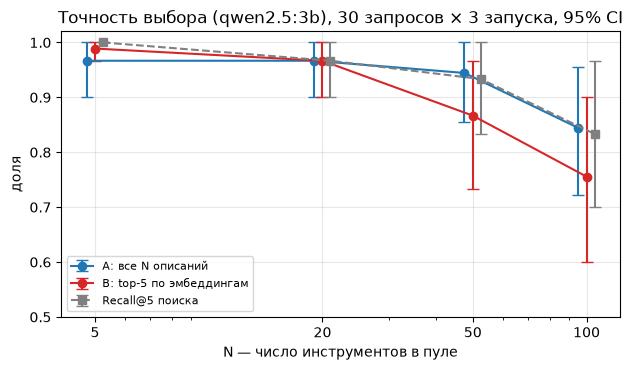

In [4]:
fig, ax = plt.subplots(figsize=(6.4, 3.8))
for v, color, label, dx in [('A', '#1f77b4', 'A: все N описаний', 0.95), ('B', '#d62728', 'B: top-5 по эмбеддингам', 1.0)]:
    s = summary[summary.variant==v].sort_values('N')
    ax.errorbar(s.N*dx, s.accuracy, yerr=[s.accuracy-s.acc_lo, s.acc_hi-s.accuracy], marker='o', capsize=4, color=color, label=label)
s = summary[summary.variant=='B'].sort_values('N')
ax.errorbar(s.N*1.05, s.recall5, yerr=[s.recall5-s.rec_lo, s.rec_hi-s.recall5], marker='s', ls='--', capsize=4, color='gray', label='Recall@5 поиска')
ax.set_xscale('log'); ax.set_xticks([5,20,50,100]); ax.set_xticklabels([5,20,50,100])
ax.set_xlabel('N — число инструментов в пуле'); ax.set_ylabel('доля'); ax.set_ylim(0.5, 1.02)
ax.set_title(f'Точность выбора ({CHAT_MODEL}), 30 запросов × 3 запуска, 95% CI'); ax.grid(alpha=.3); ax.legend(fontsize=8, loc='lower left')
fig.tight_layout(); fig.savefig(RESULTS/'accuracy_vs_N.png', dpi=200); fig.savefig(RESULTS/'accuracy_vs_N.pdf')

### Таблица токенов (среднее число входных токенов на запрос, `prompt_eval_count` из Ollama)

In [5]:
tokens = summary.pivot(index='N', columns='variant', values='mean_input_tokens')
tokens['B / A'] = tokens['B'] / tokens['A']
tokens.to_csv(RESULTS/'part_a_tokens.csv'); tokens.round({'A': 0, 'B': 0, 'B / A': 2})

variant,A,B,B / A
N,,,
5,750.000,750.000,1.000
20,1757.000,882.000,0.500
50,3993.000,1057.000,0.260
100,7734.000,1041.000,0.130


### Разрез: запросы к своим инструментам и «почти похожие» запросы (gold — отвлекающий инструмент)

In [6]:
A['gold_kind'] = A.gold.map(pool.set_index('name').kind)
by_kind = A.groupby(['gold_kind','N','variant']).correct.mean().unstack('variant')
by_kind.to_csv(RESULTS/'part_a_by_kind.csv'); by_kind

variant           A     B
gold_kind N              
near      5   1.000 1.000
          20  1.000 1.000
          50  1.000 1.000
          100 0.889 1.000
own       5   0.958 0.986
          20  0.958 0.958
          50  0.931 0.833
          100 0.833 0.694

In [7]:
# Какие инструменты модель выбирает по ошибке (все N, оба варианта)
wrong = A[(~A.correct) & (A.status=='ok')]
pd.crosstab(wrong.gold, wrong.selected.fillna('<нет вызова>')).stack().loc[lambda s: s>0].sort_values(ascending=False).head(15)

gold                   selected                   
consult_list_bookings  consult_cancel                 12
                       <нет вызова>                    7
consult_book           <нет вызова>                    6
consult_get_slot       consult_search_slots            6
                       <нет вызова>                    5
consult_list_bookings  course_get_teacher_contacts     3
                       consult_get_booking             3
consult_get_slot       exam_get_schedule               3
                       consult_get_booking             3
consult_book           course_submit_homework          3
                       consult_search_slots            3
                       reminder_create                 2
                       course_list_materials           2
course_get_deadlines   course_get_grades               2
consult_book           consult_get_slot                1
dtype: int64

## Часть B. Петли: три условия

In [8]:
B = pd.DataFrame([json.loads(l) for l in open(ROOT/'experiment/logs/part_b.jsonl', encoding='utf-8')])
tasks = json.load(open(ROOT/'experiment/data/loop_tasks.json', encoding='utf-8'))
print('эпизодов:', len(B), '| ожидалось:', 4*len(tasks), '| статусы:', B.status.value_counts().to_dict())
B['success'] = B['success'].fillna(False).astype(bool)
def ci(x):
    m, lo, hi = bootstrap_ci(np.asarray(x, dtype=float)); return f'{m:.2f} [{lo:.2f}; {hi:.2f}]'
order = ['no_guard', 'guard', 'hint', 'stable']
names = {'no_guard': 'пустой ответ, без LoopGuard', 'guard': 'пустой ответ + LoopGuard (3/6)',
         'hint': 'ответ с подсказкой, без LoopGuard', 'stable': 'контроль: стабильный инструмент'}
table = pd.DataFrame({c: {
    'эпизодов': len(g), 'доля с петлёй': ci(g.loop.fillna(True)), 'успех': ci(g.success),
    'шагов LLM (ср.)': g.turns.mean(), 'вызовов инструментов (ср.)': g.tool_calls.mean(),
    'токенов (ср.)': g.tokens.mean(), 'срабатываний guard': int(g.guard_triggers.sum()),
    'окончание': g.end.value_counts().to_dict()} for c, g in B.groupby('condition')}).T.loc[order]
table.index = [names[i] for i in table.index]
table.to_csv(RESULTS/'part_b_loops.csv'); table

эпизодов: 80 | ожидалось: 80 | статусы: {'ok': 80}


,эпизодов,доля с петлёй,успех,шагов LLM (ср.),вызовов инструментов (ср.),токенов (ср.),срабатываний guard,окончание
"пустой ответ, без LoopGuard",20,0.05 [0.00; 0.15],0.70 [0.50; 0.90],5.250,4.300,14617.100,0,"{'final_answer': 19, 'max_turns': 1}"
пустой ответ + LoopGuard (3/6),20,0.05 [0.00; 0.15],0.65 [0.45; 0.85],5.150,4.200,14223.900,1,"{'final_answer': 19, 'max_turns': 1}"
"ответ с подсказкой, без LoopGuard",20,0.00 [0.00; 0.00],0.60 [0.40; 0.80],5.250,4.250,14325.200,0,{'final_answer': 20}
контроль: стабильный инструмент,20,0.00 [0.00; 0.00],0.75 [0.55; 0.90],4.300,3.300,11681.300,0,{'final_answer': 20}


### Режимы отказа

Пустой ответ ломает агента не только петлями. Для каждого эпизода считаем: была ли попытка записать
**несуществующий слот** (slot_id выдуман моделью: ошибка «не найден»), закончился ли эпизод **без записи**
(отказ или преждевременный ответ), и сколько пустых или «ничего не найдено» ответов поиска получил агент.

In [9]:
def modes(r):
    tr = r.trace if isinstance(r.trace, list) else []
    calls = [s for s in tr if 'tool' in s]
    booked = any(s['tool'] == 'consult_book' and not s['is_error'] for s in calls)
    return pd.Series({
        'выдуманный slot_id': any(s['tool'] == 'consult_book' and 'не найден' in (s['result'] or '') for s in calls),
        'нет ни одной брони': not booked,
        'пустых/«ничего не найдено» ответов поиска': sum(s['tool'] == 'consult_search_slots' and (s['result'] == '' or s['result'].startswith('Ничего не найдено')) for s in calls),
    })
fm = B.join(B.apply(modes, axis=1)).groupby('condition')[['выдуманный slot_id', 'нет ни одной брони', 'пустых/«ничего не найдено» ответов поиска']].mean().loc[order]
fm.index = [names[i] for i in fm.index]
fm.to_csv(RESULTS/'part_b_failure_modes.csv'); fm.round(2)

,выдуманный slot_id,нет ни одной брони,пустых/«ничего не найдено» ответов поиска
"пустой ответ, без LoopGuard",0.150,0.150,0.750
пустой ответ + LoopGuard (3/6),0.150,0.200,0.750
"ответ с подсказкой, без LoopGuard",0.100,0.250,1.150
контроль: стабильный инструмент,0.000,0.050,0.000


In [10]:
# Типичная петля из лога (первая найденная в условии no_guard)
ep = B[(B.condition=='no_guard') & (B.loop==True)].head(1)
for _, r in ep.iterrows():
    print(r.task_id)
    for s in r.trace[:10]:
        print(' ', s.get('turn'), s.get('tool'), json.dumps(s.get('args'), ensure_ascii=False)[:90], '->', repr((s.get('result') or s.get('final_text') or '')[:60]))

t02
  1 consult_search_slots {"format": "online", "limit": 5, "only_free": true, "date": "2026-10-13", "teacher": "smir -> ''
  2 consult_book {"slot_id": "s-1013-iva-1000", "student_id": "st-1002", "topic": "exam", "idempotency_key" -> "Ошибка: Слот 's-1013-iva-1000' не найден. Как исправить: воз"
  3 consult_search_slots {"limit": 5, "only_free": true, "teacher": "smirnova", "topic": "exam", "date": "2026-10-1 -> ''
  4 consult_book {"student_id": "st-1002", "topic": "exam", "idempotency_key": "key-1002", "slot_id": "s-10 -> "Ошибка: Слот 's-1013-iva-1000' не найден. Как исправить: воз"
  5 consult_search_slots {"date": "2026-10-14", "format": "online", "limit": 5, "only_free": true, "teacher": "smir -> ''
  6 consult_book {"idempotency_key": "key-1002", "slot_id": "s-1014-iva-1000", "student_id": "st-1002", "to -> "Ошибка: Тема 'exam' не принимается в слоте s-1014-iva-1000. "
  7 consult_search_slots {"date": "2026-10-14", "format": "online", "limit": 5, "only_free": true, "teacher"